In [ ]:
#importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
#Load Dataset
dataset = pd.read_csv("student-mat.csv", sep=";")

In [ ]:
#Summarize data
dataset

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


In [ ]:
dataset.head(10)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
5,GP,M,16,U,LE3,T,4,3,services,other,...,5,4,2,1,2,5,10,15,15,15
6,GP,M,16,U,LE3,T,2,2,other,other,...,4,4,4,1,1,3,0,12,12,11
7,GP,F,17,U,GT3,A,4,4,other,teacher,...,4,1,4,1,1,1,6,6,5,6
8,GP,M,15,U,LE3,A,3,2,services,other,...,4,2,2,1,1,1,0,16,18,19
9,GP,M,15,U,GT3,T,3,4,other,other,...,5,5,1,1,1,5,0,14,15,15


In [ ]:
print(dataset)

    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
390     MS   M   20       U     LE3       A     2     2  services  services   
391     MS   M   17       U     LE3       T     3     1  services  services   
392     MS   M   21       R     GT3       T     1     1     other     other   
393     MS   M   18       R     LE3       T     3     2  services     other   
394     MS   M   19       U     LE3       T     1     1     other   at_home   

     ... famrel freetime  goout  Dalc  Walc health 

In [ ]:
print(type(dataset))

<class 'pandas.core.frame.DataFrame'>


In [ ]:
print("Keys of dataset:\n", dataset.keys())

Keys of dataset:
 Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')


In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [ ]:
print(f"There are {dataset.shape[1]} features in the dataset.")

There are 33 features in the dataset.


In [ ]:
print(f"There are {dataset.size} data points.")

There are 13035 data points.


In [ ]:
print(set(dataset.dtypes))

{dtype('int64'), dtype('O')}


In [ ]:
df= dataset.copy()

In [ ]:
# Explicitly define the target column based on the problem
target_col = 'G3'

# Show unique values
print(f"Target column selected: {target_col}")
print("Unique values in the target column:")
print(df[target_col].unique())

# Check data type
print("Data type of target column:", df[target_col].dtype)

# Classification or regression check
if df[target_col].dtype == 'object' or df[target_col].nunique() <= 10:
    print(" This is a Classification Problem.")
else:
    print(" This appears to be a Regression Problem.")

Target column selected: G3
Unique values in the target column:
[ 6 10 15 11 19  9 12 14 16  5  8 17 18 13 20  7  0  4]
Data type of target column: int64
 This appears to be a Regression Problem.


In [ ]:
feature_names = dataset.columns.tolist()
df3 = pd.DataFrame(dataset, columns=feature_names[1:])

In [ ]:
df3 = dataset

quantitative_data = df3.select_dtypes(include=['number'])
quantitative_features = quantitative_data.columns.tolist()

categorical_data = df3.select_dtypes(include=['object'])
categorical_features = categorical_data.columns.tolist()

print(f"No of Quantitative features {len(quantitative_features)}")
print("Quantitative:", quantitative_features)

print(f"No of Categorical features {len(categorical_features)}")
print("Categorical:", categorical_features)

No of Quantitative features 16
Quantitative: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
No of Categorical features 17
Categorical: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


***EDA(Exploratory Data Analysis)***

In [ ]:
# Transposed stats for quantitative features
quantitative_data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


In [ ]:
# Transposed stats for categorical features
categorical_data.describe().T

,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344


In [ ]:
quantitative_data.var()

,0
age,1.628285
Medu,1.198445
Fedu,1.184180
traveltime,0.486513
studytime,0.704324
failures,0.553017
famrel,0.803997
freetime,0.997725
goout,1.239388
Dalc,0.793420


In [ ]:
quantitative_data.skew()

,0
age,0.466270
Medu,-0.318381
Fedu,-0.031672
traveltime,1.607029
studytime,0.632142
failures,2.387026
famrel,-0.951882
freetime,-0.163351
goout,0.116502
Dalc,2.190762


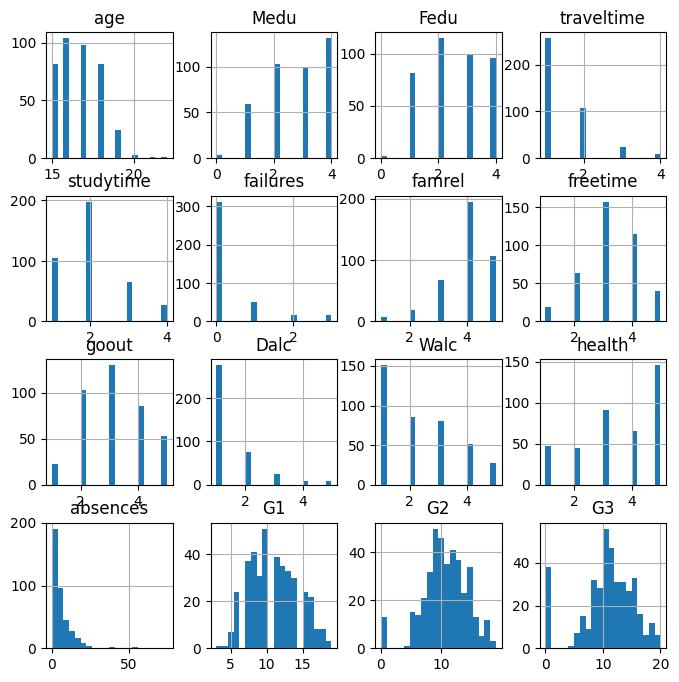

In [ ]:
quantitative_data.hist(figsize=(8,8),bins=20)
plt.show()

In [ ]:
#Number Unique values in quantitative feature
quantitative_data.nunique()

,0
age,8
Medu,5
Fedu,5
traveltime,4
studytime,4
failures,4
famrel,5
freetime,5
goout,5
Dalc,5


In [ ]:
#Number Unique values in quantitative feature
categorical_data.nunique()

,0
school,2
sex,2
address,2
famsize,2
Pstatus,2
Mjob,5
Fjob,5
reason,4
guardian,3
schoolsup,2


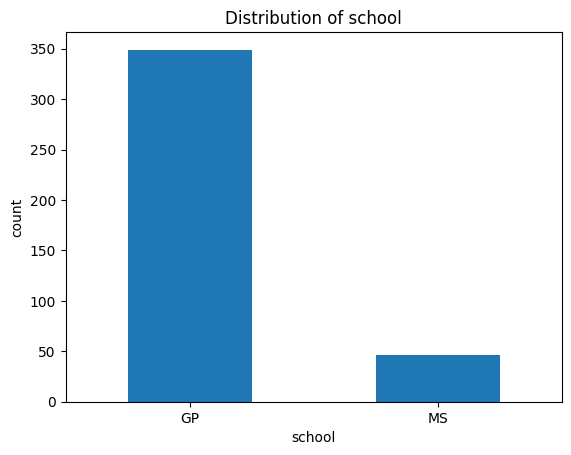

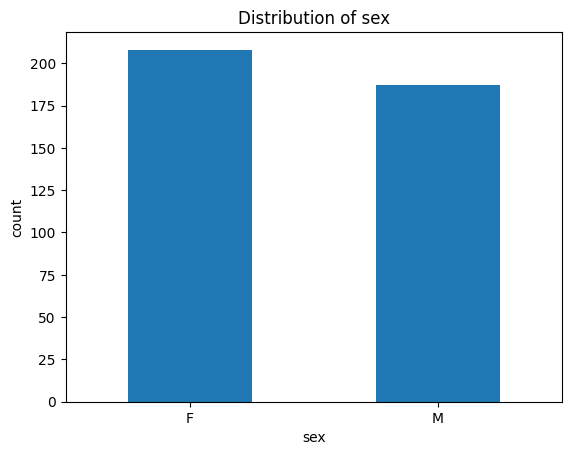

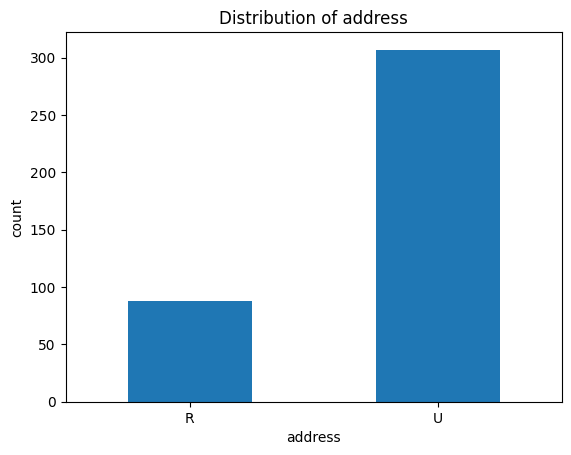

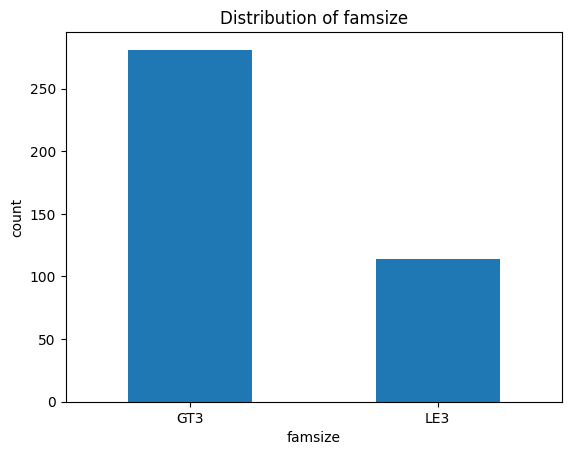

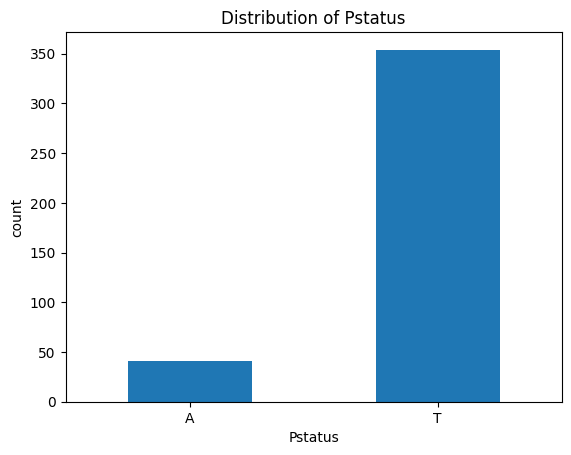

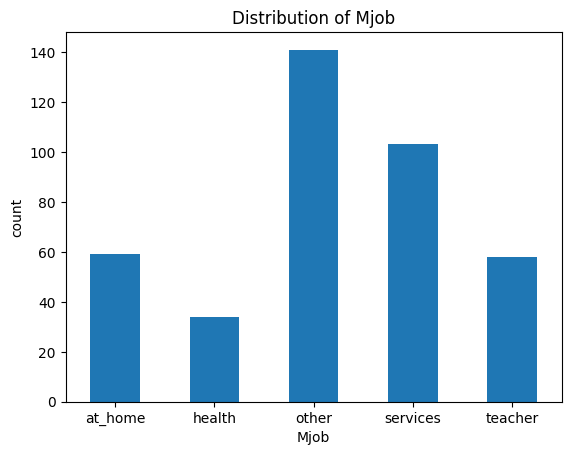

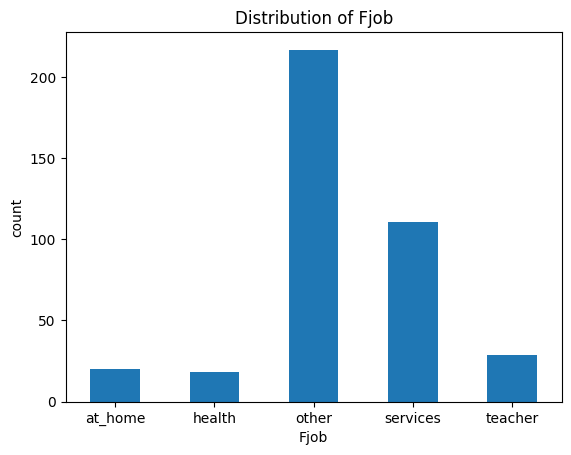

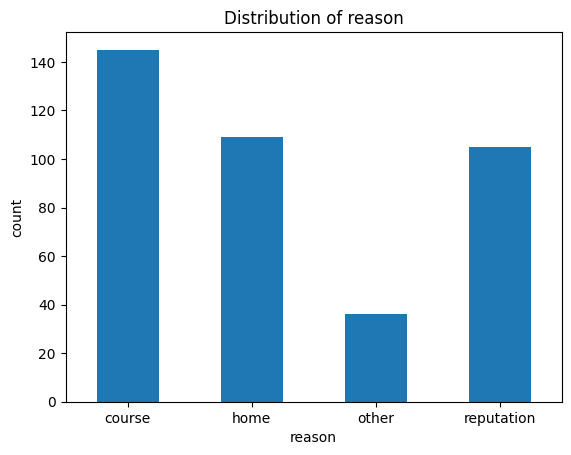

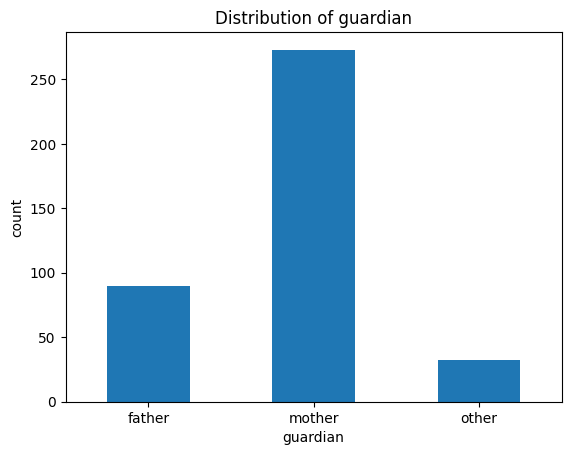

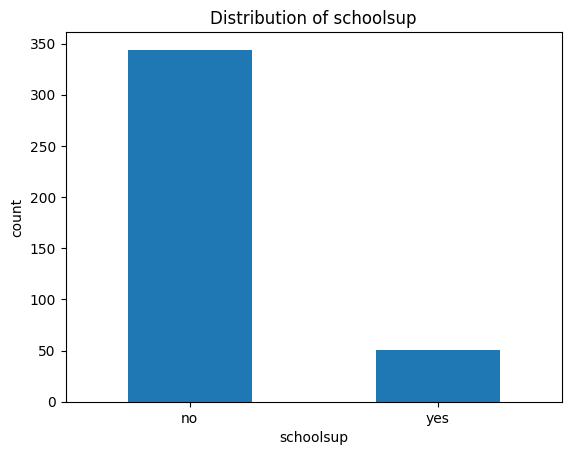

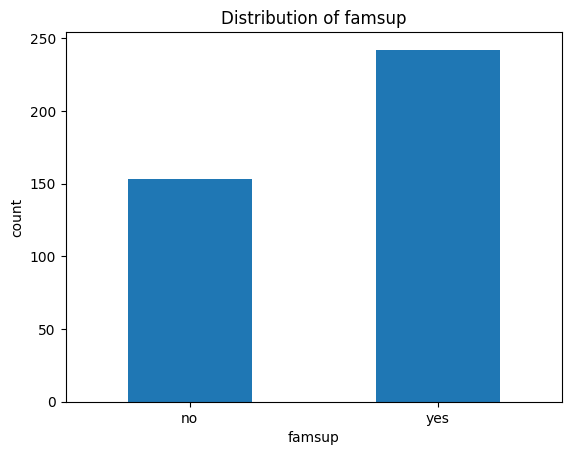

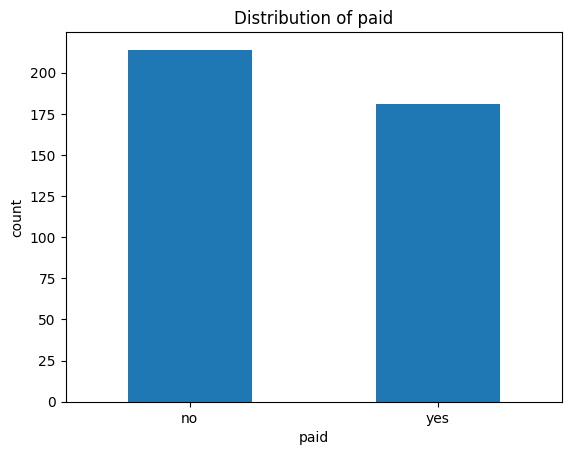

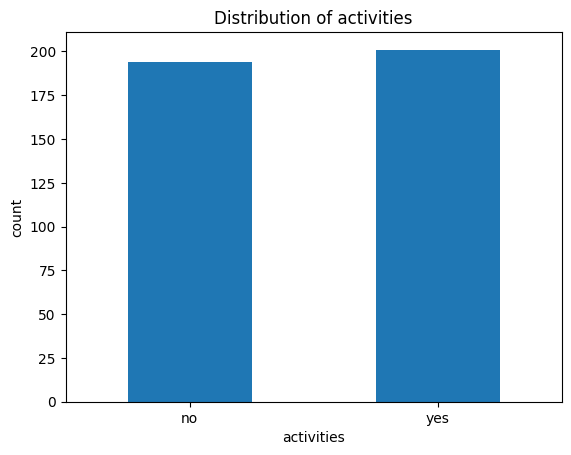

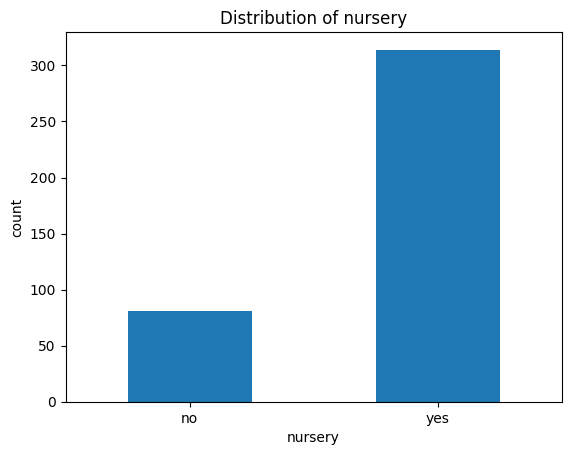

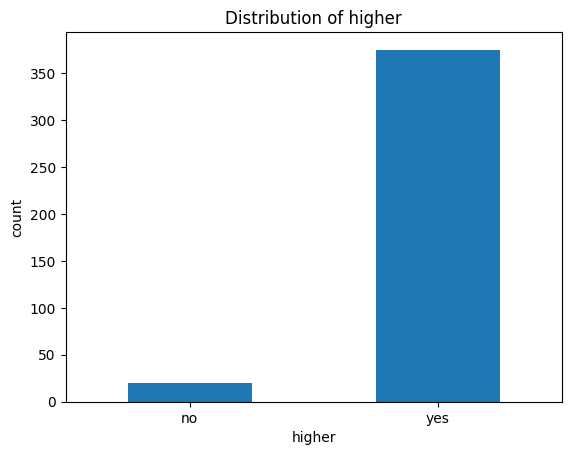

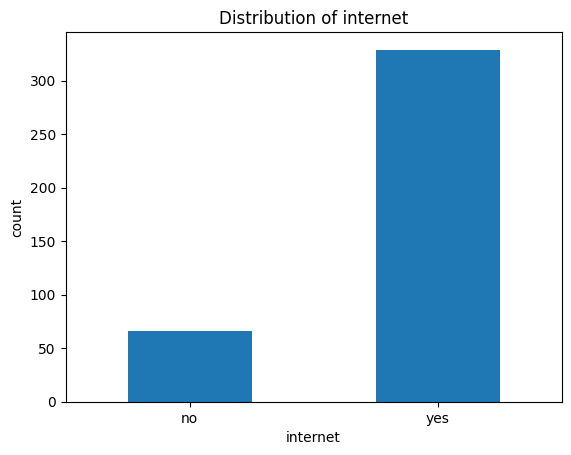

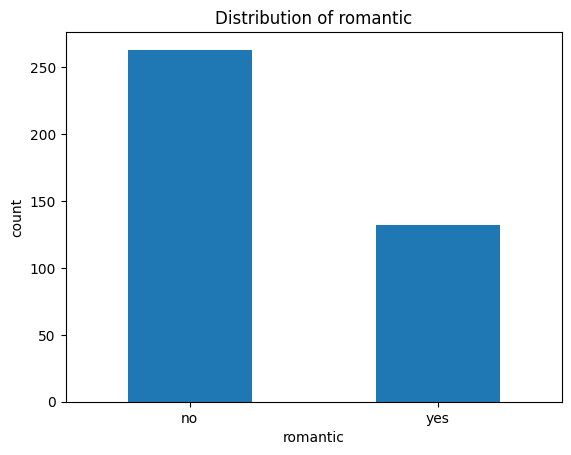

In [ ]:
#Barplot of unique value counts in every categorical features
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

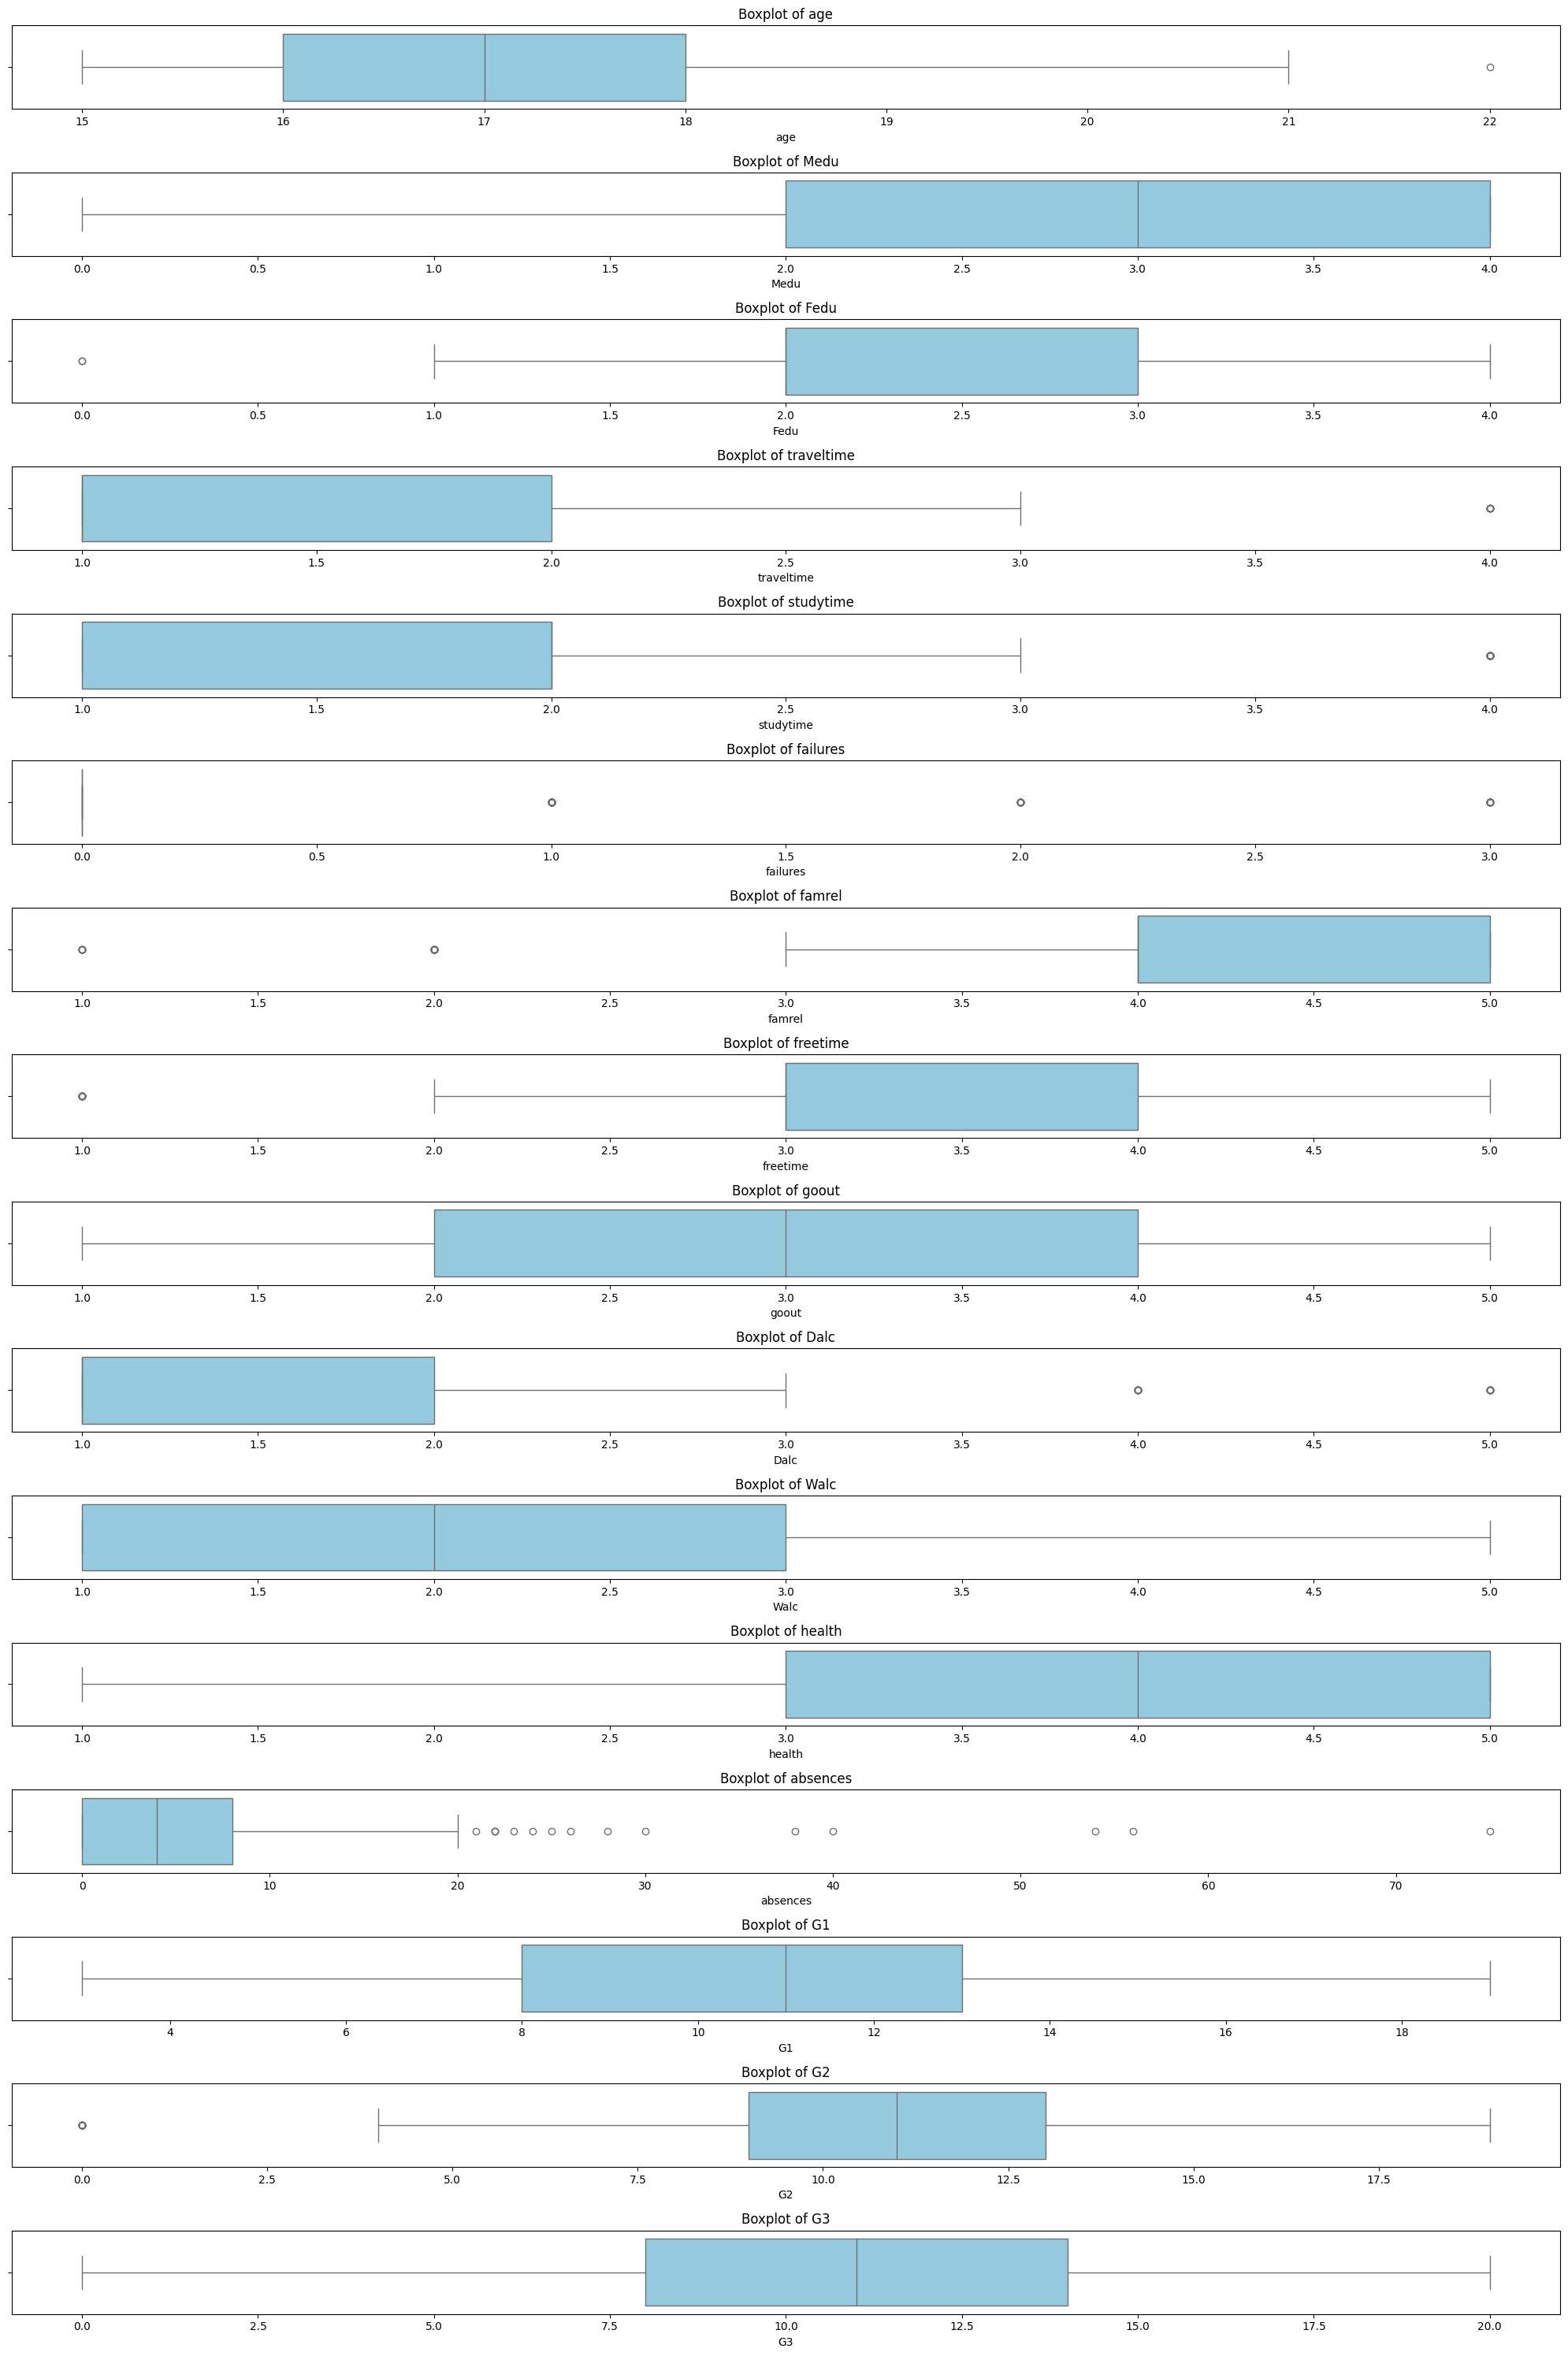

In [ ]:
# Select only numerical columns for boxplot analysis
quantitative_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'G3'
for i, col in enumerate(quantitative_cols, 1):
    plt.subplot(len(quantitative_cols), 1, i)
    sns.boxplot(x=df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

In [ ]:
# Calculate the correlation matrix
correlation_matrix = quantitative_data.corr()
correlation_matrix

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
age,1.000000,-0.163658,-0.163438,0.070641,-0.004140,0.243665,0.053940,0.016434,0.126964,0.131125,0.117276,-0.062187,0.175230,-0.064081,-0.143474,-0.161579
Medu,-0.163658,1.000000,0.623455,-0.171639,0.064944,-0.236680,-0.003914,0.030891,0.064094,0.019834,-0.047123,-0.046878,0.100285,0.205341,0.215527,0.217147
Fedu,-0.163438,0.623455,1.000000,-0.158194,-0.009175,-0.250408,-0.001370,-0.012846,0.043105,0.002386,-0.012631,0.014742,0.024473,0.190270,0.164893,0.152457
traveltime,0.070641,-0.171639,-0.158194,1.000000,-0.100909,0.092239,-0.016808,-0.017025,0.028540,0.138325,0.134116,0.007501,-0.012944,-0.093040,-0.153198,-0.117142
studytime,-0.004140,0.064944,-0.009175,-0.100909,1.000000,-0.173563,0.039731,-0.143198,-0.063904,-0.196019,-0.253785,-0.075616,-0.062700,0.160612,0.135880,0.097820
failures,0.243665,-0.236680,-0.250408,0.092239,-0.173563,1.000000,-0.044337,0.091987,0.124561,0.136047,0.141962,0.065827,0.063726,-0.354718,-0.355896,-0.360415
famrel,0.053940,-0.003914,-0.001370,-0.016808,0.039731,-0.044337,1.000000,0.150701,0.064568,-0.077594,-0.113397,0.094056,-0.044354,0.022168,-0.018281,0.051363
freetime,0.016434,0.030891,-0.012846,-0.017025,-0.143198,0.091987,0.150701,1.000000,0.285019,0.209001,0.147822,0.075733,-0.058078,0.012613,-0.013777,0.011307
goout,0.126964,0.064094,0.043105,0.028540,-0.063904,0.124561,0.064568,0.285019,1.000000,0.266994,0.420386,-0.009577,0.044302,-0.149104,-0.162250,-0.132791
Dalc,0.131125,0.019834,0.002386,0.138325,-0.196019,0.136047,-0.077594,0.209001,0.266994,1.000000,0.647544,0.077180,0.111908,-0.094159,-0.064120,-0.054660


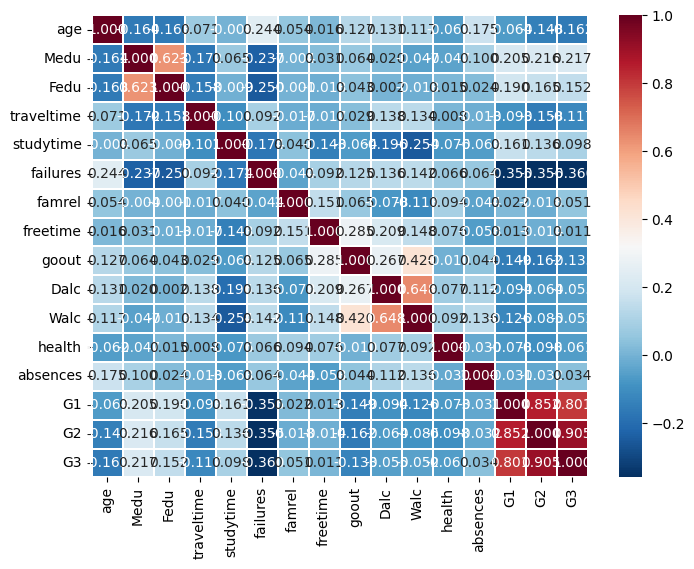

In [ ]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='RdBu_r', fmt='.3f', linewidths=0.3)
plt.show()

**Dataset pre-processing**

**1.Null Values**

In [ ]:
# Check for missing values
null = df.isnull().sum()
null_pct = (null / len(df) * 100).round(2)

null_table = pd.DataFrame({
    "null(0)": null,
    "null_%": null_pct
})

print(null_table)


            null(0)  null_%
school            0     0.0
sex               0     0.0
age               0     0.0
address           0     0.0
famsize           0     0.0
Pstatus           0     0.0
Medu              0     0.0
Fedu              0     0.0
Mjob              0     0.0
Fjob              0     0.0
reason            0     0.0
guardian          0     0.0
traveltime        0     0.0
studytime         0     0.0
failures          0     0.0
schoolsup         0     0.0
famsup            0     0.0
paid              0     0.0
activities        0     0.0
nursery           0     0.0
higher            0     0.0
internet          0     0.0
romantic          0     0.0
famrel            0     0.0
freetime          0     0.0
goout             0     0.0
Dalc              0     0.0
Walc              0     0.0
health            0     0.0
absences          0     0.0
G1                0     0.0
G2                0     0.0
G3                0     0.0


In [ ]:
NULL = dataset.isnull().sum().sum()
print(f"Total NULL Values: {NULL}")

Total NULL Values: 0


In [ ]:
dataset.shape

(395, 33)

In [ ]:
# Drop redundant features/columns
df = df.drop(['school', 'address', 'famsize', 'Pstatus'], axis=1) #axis=1 is column, 0 is row
df

,sex,age,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,F,18,4,4,at_home,teacher,course,mother,2,2,...,4,3,4,1,1,3,6,5,6,6
1,F,17,1,1,at_home,other,course,father,1,2,...,5,3,3,1,1,3,4,5,5,6
2,F,15,1,1,at_home,other,other,mother,1,2,...,4,3,2,2,3,3,10,7,8,10
3,F,15,4,2,health,services,home,mother,1,3,...,3,2,2,1,1,5,2,15,14,15
4,F,16,3,3,other,other,home,father,1,2,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,M,20,2,2,services,services,course,other,1,2,...,5,5,4,4,5,4,11,9,9,9
391,M,17,3,1,services,services,course,mother,2,1,...,2,4,5,3,4,2,3,14,16,16
392,M,21,1,1,other,other,course,other,1,1,...,5,5,3,3,3,3,3,10,8,7
393,M,18,3,2,services,other,course,mother,3,1,...,4,4,1,3,4,5,0,11,12,10


In [ ]:
# Drop duplicates
df = df.drop_duplicates()
df

,sex,age,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,F,18,4,4,at_home,teacher,course,mother,2,2,...,4,3,4,1,1,3,6,5,6,6
1,F,17,1,1,at_home,other,course,father,1,2,...,5,3,3,1,1,3,4,5,5,6
2,F,15,1,1,at_home,other,other,mother,1,2,...,4,3,2,2,3,3,10,7,8,10
3,F,15,4,2,health,services,home,mother,1,3,...,3,2,2,1,1,5,2,15,14,15
4,F,16,3,3,other,other,home,father,1,2,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,M,20,2,2,services,services,course,other,1,2,...,5,5,4,4,5,4,11,9,9,9
391,M,17,3,1,services,services,course,mother,2,1,...,2,4,5,3,4,2,3,14,16,16
392,M,21,1,1,other,other,course,other,1,1,...,5,5,3,3,3,3,3,10,8,7
393,M,18,3,2,services,other,course,mother,3,1,...,4,4,1,3,4,5,0,11,12,10


**Categorical Encoding**

**One-hot Encoding**

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Load dataset
df2 = dataset.copy()

# Separate categorical and numerical columns
cat_cols = df2.select_dtypes(include=['object']).columns
num_cols = df2.select_dtypes(exclude=['object']).columns

# One-hot encoder
encoder = OneHotEncoder(sparse_output=False, drop='first')

# Encode categorical data
encoded_cat = encoder.fit_transform(df2[cat_cols])

# Convert to DataFrame
encoded_cat_df = pd.DataFrame(
    encoded_cat,
    columns=encoder.get_feature_names_out(cat_cols)
)

# Combine with numerical data
df2_final = pd.concat([df2[num_cols], encoded_cat_df], axis=1)

print(df2_final.head())

   age  Medu  Fedu  traveltime  studytime  failures  famrel  freetime  goout  \
0   18     4     4           2          2         0       4         3      4   
1   17     1     1           1          2         0       5         3      3   
2   15     1     1           1          2         3       4         3      2   
3   15     4     2           1          3         0       3         2      2   
4   16     3     3           1          2         0       4         3      2   

   Dalc  ...  guardian_mother  guardian_other  schoolsup_yes  famsup_yes  \
0     1  ...              1.0             0.0            1.0         0.0   
1     1  ...              0.0             0.0            0.0         1.0   
2     2  ...              1.0             0.0            1.0         0.0   
3     1  ...              1.0             0.0            0.0         1.0   
4     1  ...              0.0             0.0            0.0         1.0   

   paid_yes  activities_yes  nursery_yes  higher_yes  internet

**Feature Scaling**

In [ ]:
from sklearn.preprocessing import StandardScaler

df4 = df2_final.copy()  # After applying One-Hot Encoding dataset

# Separate features and target
X = df4.drop(columns=["G3"])
y = df4["G3"]

# Scale only TRUE continuous numeric features
num_cols = [
    c for c in [
        "age", "Medu", "Fedu", "traveltime", "studytime",
        "failures", "famrel", "freetime", "goout",
        "Dalc", "Walc", "health", "absences",
        "G1", "G2"
    ] if c in X.columns
]

scaler = StandardScaler()
X[num_cols] = scaler.fit_transform(X[num_cols])

print("Scaled columns:", num_cols)

Scaled columns: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


**Final Preprocessed Dataset**

In [ ]:
# Combine features and target for inspection
df_preprocessed = X.copy()
df_preprocessed['G3'] = y

# Final shape check
print("Final preprocessed dataset shape:", df_preprocessed.shape)
print(df_preprocessed.head())

Final preprocessed dataset shape: (395, 42)
        age      Medu      Fedu  traveltime  studytime  failures    famrel  \
0  1.023046  1.143856  1.360371    0.792251  -0.042286 -0.449944  0.062194   
1  0.238380 -1.600009 -1.399970   -0.643249  -0.042286 -0.449944  1.178860   
2 -1.330954 -1.600009 -1.399970   -0.643249  -0.042286  3.589323  0.062194   
3 -1.330954  1.143856 -0.479857   -0.643249   1.150779 -0.449944 -1.054472   
4 -0.546287  0.229234  0.440257   -0.643249  -0.042286 -0.449944  0.062194   

   freetime     goout      Dalc  ...  guardian_other  schoolsup_yes  \
0 -0.236010  0.801479 -0.540699  ...             0.0            1.0   
1 -0.236010 -0.097908 -0.540699  ...             0.0            0.0   
2 -0.236010 -0.997295  0.583385  ...             0.0            1.0   
3 -1.238419 -0.997295 -0.540699  ...             0.0            0.0   
4 -0.236010 -0.997295 -0.540699  ...             0.0            0.0   

   famsup_yes  paid_yes  activities_yes  nursery_yes  higher

**Dataset Splitting**

In [ ]:
df5 = df_preprocessed.copy()

# Separate features and target
X = df5.drop('G3', axis=1)   # all columns except the target
y = df5['G3']

# Train-test split (NO stratify because G3 is continuous)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (316, 41)
y_train shape: (316,)
X_test shape: (79, 41)
y_test shape: (79,)


In [ ]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("per-feature minimum after scaling:\n {}".format(X_train_scaled.min(axis=0)))
print("per-feature maximum after scaling:\n {}".format(X_train_scaled.max(axis=0)))

per-feature minimum after scaling:
 [-1.37491159 -2.5347818  -2.36290781 -0.62577865 -1.25455313 -0.45674383
 -3.32899535 -2.17761729 -1.9337737  -0.55443033 -1.03908875 -1.78844346
 -0.70225668 -1.84746101 -2.84051948 -0.34722813 -0.92672732 -1.89201219
 -0.63105474 -2.97909382 -0.30565602 -0.73073975 -0.60172167 -0.40219983
 -0.23094011 -1.13571787 -0.59684435 -0.26680787 -0.60172167 -0.33567254
 -0.59684435 -1.50257511 -0.30565602 -0.40219983 -1.23612297 -0.92084375
 -0.99369079 -2.00396433 -4.06885187 -2.27949083 -0.72565146]
per-feature maximum after scaling:
 [4.14469718 1.17351009 1.35191243 3.73626663 2.33854767 3.62809723
 1.19557467 1.74892801 1.64498172 3.88101234 2.05128343 1.05149691
 8.21708058 2.51156166 2.22617064 2.87995098 1.07906606 0.52853782
 1.58464858 0.33567254 3.27165153 1.36847626 1.66189794 2.48632624
 4.33012702 0.88050037 1.67547871 3.74801535 1.66189794 2.97909382
 1.67547871 0.66552414 3.27165153 2.48632624 0.808981   1.08596056
 1.00634927 0.49901088 0.2

array([[<Axes: xlabel='age', ylabel='age'>,
        <Axes: xlabel='studytime', ylabel='age'>,
        <Axes: xlabel='failures', ylabel='age'>,
        <Axes: xlabel='absences', ylabel='age'>,
        <Axes: xlabel='G1', ylabel='age'>,
        <Axes: xlabel='G2', ylabel='age'>],
       [<Axes: xlabel='age', ylabel='studytime'>,
        <Axes: xlabel='studytime', ylabel='studytime'>,
        <Axes: xlabel='failures', ylabel='studytime'>,
        <Axes: xlabel='absences', ylabel='studytime'>,
        <Axes: xlabel='G1', ylabel='studytime'>,
        <Axes: xlabel='G2', ylabel='studytime'>],
       [<Axes: xlabel='age', ylabel='failures'>,
        <Axes: xlabel='studytime', ylabel='failures'>,
        <Axes: xlabel='failures', ylabel='failures'>,
        <Axes: xlabel='absences', ylabel='failures'>,
        <Axes: xlabel='G1', ylabel='failures'>,
        <Axes: xlabel='G2', ylabel='failures'>],
       [<Axes: xlabel='age', ylabel='absences'>,
        <Axes: xlabel='studytime', ylabel='absen

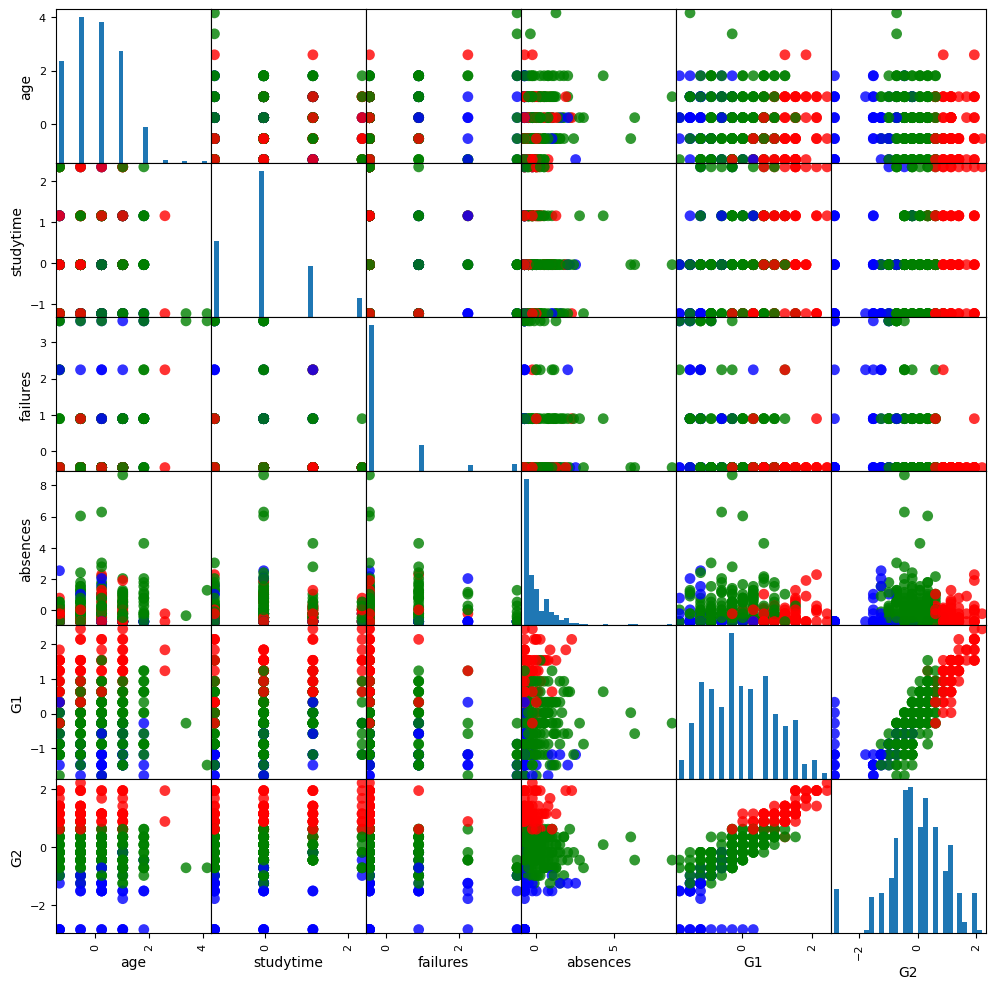

In [ ]:
# Pick numeric features from student-mat
selected_features = [
    'age', 'studytime', 'failures',
    'absences', 'G1', 'G2'
]

# Make the plotting frame from your train split
df7 = X_train[selected_features].copy()

# Color by G3 (continuous → use bins)
y_colors = pd.cut(y_train, bins=3, labels=['blue', 'green', 'red'])

pd.plotting.scatter_matrix(
    df7,
    c=y_colors,
    figsize=(12, 12),
    marker='o',
    hist_kwds={'bins': 30},
    s=60,
    alpha=0.8
)

**Random Forest**

**Model Training**

In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

RandomForestRegressor(random_state=42)

**Model Prediction**

In [ ]:
rf_y_pred = rf_model.predict(X_test_scaled)
print("First 100 test set predictions using Random Forest:\n", rf_y_pred[:100])

First 100 test set predictions using Random Forest:
 [ 8.32 11.76  6.54  9.77  8.8  12.84 18.7   6.71  6.68 13.36 15.64  6.81
 13.92 11.89 14.11  8.31  1.14 10.57 15.45  6.25 14.14 15.65 15.26  6.27
  6.24 18.49 10.44  9.68 18.27 10.62  8.49  8.48 15.27 13.07  1.03  6.35
  0.13 15.07 11.75  7.76  6.46 10.13 14.02  8.48 14.89  6.35 11.58 14.29
 12.73 15.58 13.46 15.35 10.04  8.64  5.61 13.26 10.8   1.48 15.57 16.01
 13.3   8.72  8.32  6.21  7.22 18.28  9.6   9.32  9.68 15.29  8.35  9.87
 13.63 18.42 10.73  5.85  8.9  14.2   5.78]


**Model Evaluation**

In [ ]:
rf_mse = mean_squared_error(y_test, rf_y_pred)
rf_r2 = r2_score(y_test, rf_y_pred)

print("Mean Squared Error using Random Forest: {:.2f}".format(rf_mse))
print("R2 Score (Accuracy) using Random Forest: {:.2f}".format(rf_r2))

Mean Squared Error using Random Forest: 3.83
R2 Score (Accuracy) using Random Forest: 0.81


**Linear Regression**

**Model Training**

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

LinearRegression()

**Model Prediction**

In [ ]:
lr_y_pred = lr_model.predict(X_test_scaled)
print("First 100 test set predictions using Linear Regression:\n", lr_y_pred[:100])

First 100 test set predictions using Linear Regression:
 [ 6.00160699 11.52847844  2.86643677  8.79663116  8.55310627 11.88964112
 19.09674195  7.17307901  7.4050707  12.31153657 14.50202689  5.52448201
 13.64498491 11.94484589 14.6379871   8.46898698  5.84105527 10.75365252
 14.22958393  8.40257994 13.79124386 16.35136154 13.5710786   5.88531485
  8.40557156 20.82262969 10.55231057  9.277694   17.11938646 11.58080009
  9.38983351  6.68701138 14.43529558 12.78113257  5.32339752  4.15398128
 -2.57739105 15.53366365 12.09668779  6.57159416  5.45294413  9.83775897
 14.48014104  6.91378509 16.88534513  9.17660623 11.3471303  13.7703158
 11.05012149 15.87344331 14.00504973 14.33550256  9.72665558  7.37608193
  3.26326232 12.69215949 10.45929549  6.45503769 15.59150316 16.00262765
 13.54350243  7.61990637  8.10361767  4.06225543  3.1583286  16.3610109
  7.9314948   8.31470193  9.19538486 16.23839817  8.24081518  8.58890771
 13.8883608  20.47747752 10.15673983  6.27578808  7.68665599 12.40906

**Model Evaluation**

In [ ]:
lr_mse = mean_squared_error(y_test, lr_y_pred)
lr_r2 = r2_score(y_test, lr_y_pred)

print("Mean Squared Error using Linear Regression: {:.2f}".format(lr_mse))
print("R2 Score (Accuracy) using Linear Regression: {:.2f}".format(lr_r2))

Mean Squared Error using Linear Regression: 5.66
R2 Score (Accuracy) using Linear Regression: 0.72


**Gradient Boosting**

**Model Training**

In [ ]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)
gb_model.fit(X_train_scaled, y_train)

GradientBoostingRegressor(random_state=42)

**Model Prediction**

In [ ]:
gb_y_pred = gb_model.predict(X_test_scaled)
print("First 100 test set predictions using Gradient Boosting:\n", gb_y_pred[:100])

First 100 test set predictions using Gradient Boosting:
 [ 9.11210218 11.39240878  5.41837231 10.01478319  9.10949775 12.20145236
 18.21412834  7.53390901  5.63808005 12.88656777 15.29526902  6.92411639
 13.57836495 11.62379602 14.33395002  8.76062871  0.36895835 10.94456217
 13.99294057  5.11774222 13.90968526 15.36314384 14.77665813  5.98001826
  7.59303708 18.89897004 10.76267689 10.31466772 17.67814074 12.47038312
  7.81091879  9.15027367 15.31020594 12.6239742  -0.28163018  6.53612683
 -0.67834194 15.35601015 12.18259598  9.11396244  6.58798295 10.73509632
 14.53189394  8.98117868 15.10764962  7.74985833 11.50257017 14.20903048
 11.89344764 15.75885148 13.58653057 15.67277028 10.84554306  9.09479434
  6.04490864 12.46102574 10.59698786  0.89521681 14.9957621  15.57166941
 12.77507999  9.70728237  9.20115463  6.07406215  6.85562882 17.27724073
  8.96134871  9.25801024  9.38163459 15.45660088  9.20577976  9.81412859
 13.93380009 18.86598744 10.49519251  6.14496234  9.88987623 14.177

**Model Evaluation**

In [ ]:
gb_mse = mean_squared_error(y_test, gb_y_pred)
gb_r2 = r2_score(y_test, gb_y_pred)

print("Mean Squared Error using Gradient Boosting: {:.2f}".format(gb_mse))
print("R2 Score (Accuracy) using Gradient Boosting: {:.2f}".format(gb_r2))

Mean Squared Error using Gradient Boosting: 4.02
R2 Score (Accuracy) using Gradient Boosting: 0.80


**SVR**

**Model Training**

In [ ]:
svr_model = SVR(kernel='rbf', C=100, gamma='scale', epsilon=0.1)
svr_model.fit(X_train_scaled, y_train)

SVR(C=100)

**Model Prediction**

In [ ]:
svr_y_pred = svr_model.predict(X_test_scaled)
print("First 100 test set predictions using SVR:\n", svr_y_pred[:100])

First 100 test set predictions using SVR:
 [ 5.96554337 11.16784199  1.89636256 11.31269158 10.1220861  11.45187211
 17.63859055  8.07425816  6.89380742 11.88335525 14.54777875  5.50331822
 12.83447999 10.45348844 15.37596687 10.02592025  4.6223104  10.7321782
 13.18078358  7.94517983 13.43958505 14.00839853 12.3710253   6.94000688
  7.40536753 17.6804937   9.94881166  9.35399053 15.23806486 11.75600307
  9.26438655  6.48038317 15.18398528 12.03244913  1.76262763  6.56357918
  2.18521612 12.61385825 12.74108864  7.47522106  6.20843599  9.94007471
 13.7240363   5.31639998 14.75262076  7.75704822 12.18822954 14.22436605
 10.48632142 14.97989067 15.01059705 15.19083443 10.14091198  8.79974215
  4.8572131  12.82208139 11.40428941  6.78502204 14.87043223 16.11516859
 12.3618153   8.76190404  6.59618347  3.86905354  3.26811588 16.11457314
  7.07041963  7.85683524  9.57438944 15.9550787   9.72050467  8.92799981
 13.8691157  16.4246488   8.72597408  5.93264097 10.41222618 11.62284437
  5.62710

**Model Evaluation**

In [ ]:
svr_mse = mean_squared_error(y_test, svr_y_pred)
svr_r2 = r2_score(y_test, svr_y_pred)

print("Mean Squared Error using SVR: {:.2f}".format(svr_mse))
print("R2 Score (Accuracy) using SVR: {:.2f}".format(svr_r2))

Mean Squared Error using SVR: 6.79
R2 Score (Accuracy) using SVR: 0.67


**Neural Network**

**Model Training**

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Number of input features
n_features = X_train_scaled.shape[1]

# Build the model
nn_model = Sequential([
    Dense(64, activation='relu', input_shape=(n_features,)),
    Dense(32, activation='relu'),
    Dense(1)  # Single output for regression
])

# Compile the model
nn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

# Train the model
history = nn_model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 127.5920  
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 113.7446 
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 94.6397 
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 73.0041 
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 59.8938 
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 42.5274 
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 32.3355 
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 21.1015 
Epoch 9/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 15.7020 
Epoch 10/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 13.2486 
Epoch 11/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11.4686 
Epoch 12/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 9.3589  
Epoch 13/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 7.4843 
Epoch 14/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 6.8168 
Epoch 15/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 4.8780 


**Model Prediction**

In [ ]:
nn_y_pred = nn_model.predict(X_test_scaled).flatten()

print("First 100 test set predictions using Neural Network:\n", nn_y_pred[:100])

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
First 100 test set predictions using Neural Network:
 [ 5.251177   12.238573   -0.6305057  10.581266   12.092629   10.732579
 19.304472    9.505957    6.8968606  11.524001   16.290068    4.500954
 12.670776   10.36624    15.552692    6.769845    5.207091   11.209572
 12.78584     8.551048   13.265989   16.137754   11.268413    5.6259255
  4.851684   19.949915   11.180944   11.015228   15.673321   11.392723
 11.383249    7.1556573  14.978666   13.11906     4.083996    3.7164545
 -0.71283084 13.105856   12.565062    6.4428315   6.872038    9.7300205
 14.58881     6.834575   13.708565    8.893719    9.690481   12.284801
 11.790967   14.439346   14.528416   15.428701    8.831193    7.536156
  3.628813    9.829661   11.118391    7.24631    15.857857   16.131048
 14.720846    4.6286077   7.0214763   3.5834062   1.3930132  16.328106
  7.8715806   6.7419105   8.485134   17.719074    9.302626    8.540949
 14.310911   19.293095    5.7455444   9.583996    9.9

**Model Evaluation**

In [ ]:
nn_mse = mean_squared_error(y_test, nn_y_pred)
nn_r2 = r2_score(y_test, nn_y_pred)

print("Mean Squared Error using Neural Network: {:.2f}".format(nn_mse))
print("R2 Score (Accuracy) using Neural Network: {:.2f}".format(nn_r2))

Mean Squared Error using Neural Network: 8.01
R2 Score (Accuracy) using Neural Network: 0.61


In [ ]:
models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Linear Regression": LinearRegression(),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),
    "SVR": SVR(kernel='rbf', C=100, gamma='scale', epsilon=0.1),
    "Neural Network": MLPRegressor(hidden_layer_sizes=(50,), max_iter=1000, random_state=42)
}

In [ ]:
# ===== Train, predict, and evaluate =====
# Lists to store evaluation results
model_names = []
mse_list = []
r2_list = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\n🔹 Model: {name}")
    print(f"MSE : {mse:.4f}")
    print(f"R²  : {r2:.4f}")

    model_names.append(name)
    mse_list.append(mse)
    r2_list.append(r2)



🔹 Model: Random Forest
MSE : 3.8318
R²  : 0.8131

🔹 Model: Linear Regression
MSE : 5.6566
R²  : 0.7241

🔹 Model: Gradient Boosting
MSE : 4.0112
R²  : 0.8044

🔹 Model: SVR
MSE : 6.7954
R²  : 0.6686

🔹 Model: Neural Network
MSE : 7.1513
R²  : 0.6512


/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


**Predicted vs actual plot for all models**

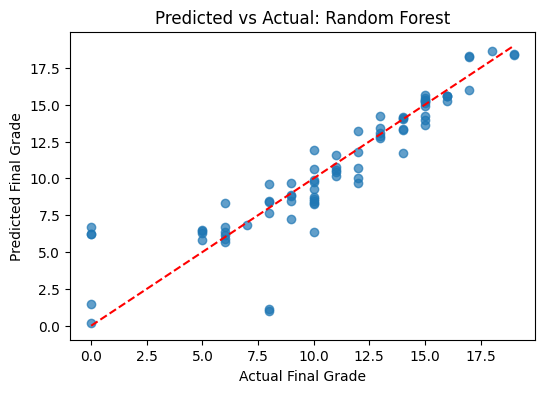

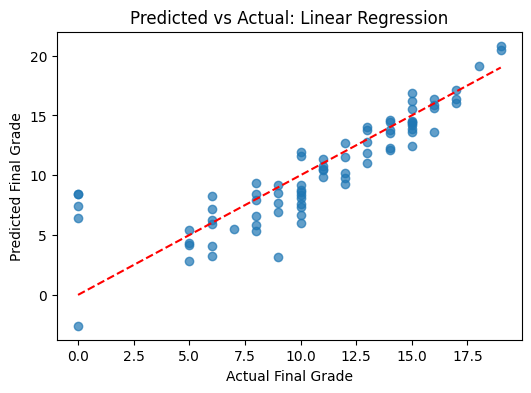

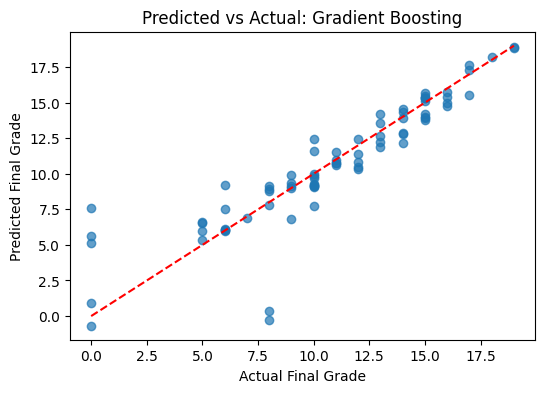

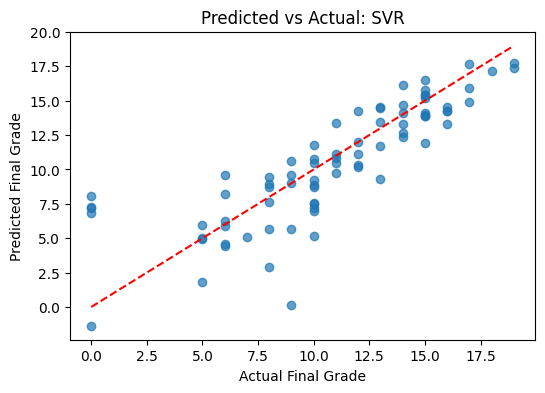

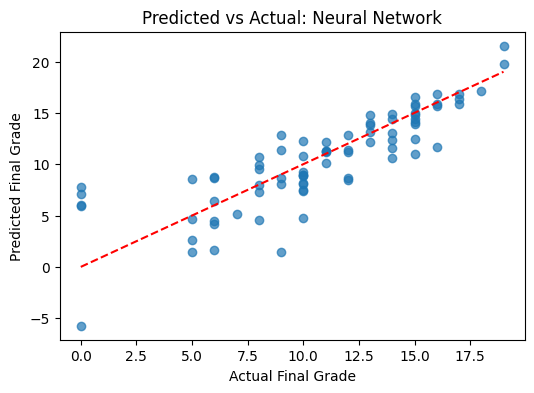

In [ ]:
# ===== Predicted vs Actual plots =====
for name, model in models.items():
    y_pred = model.predict(X_test)

    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.7)
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    plt.xlabel("Actual Final Grade")
    plt.ylabel("Predicted Final Grade")
    plt.title(f"Predicted vs Actual: {name}")
    plt.show()

**Bar Charts: R² Scores**

/tmp/ipython-input-3600257791.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model_names, y=r2_list, palette='Set2')


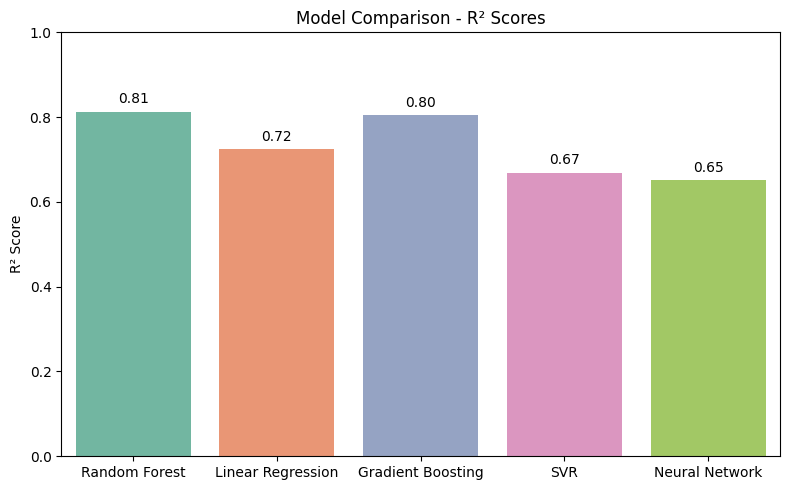

In [ ]:
# ===== R² Scores Comparison =====
plt.figure(figsize=(8, 5))
sns.barplot(x=model_names, y=r2_list, palette='Set2')
plt.title("Model Comparison - R² Scores")
plt.ylabel("R² Score")
plt.ylim(0, 1)

for i, score in enumerate(r2_list):
    plt.text(i, score + 0.02, f"{score:.2f}", ha='center', fontsize=10)

plt.tight_layout()
plt.show()

**Bar Charts: MSE**

/tmp/ipython-input-1410310911.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=model_names, y=mse_list, palette='Set3')


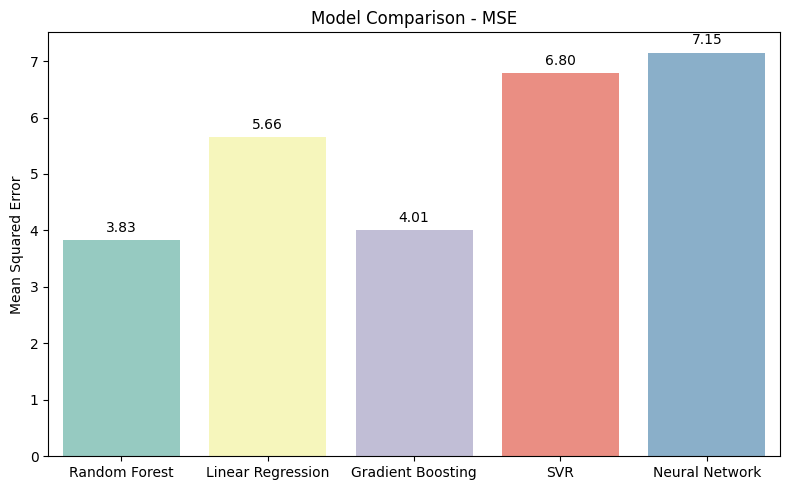

In [ ]:
# ===== MSE Comparison =====
plt.figure(figsize=(8, 5))
sns.barplot(x=model_names, y=mse_list, palette='Set3')
plt.title("Model Comparison - MSE")
plt.ylabel("Mean Squared Error")

for i, score in enumerate(mse_list):
    plt.text(i, score + 0.02*max(mse_list), f"{score:.2f}", ha='center', fontsize=10)

plt.tight_layout()
plt.show()

**Residual plots (prediction error)**

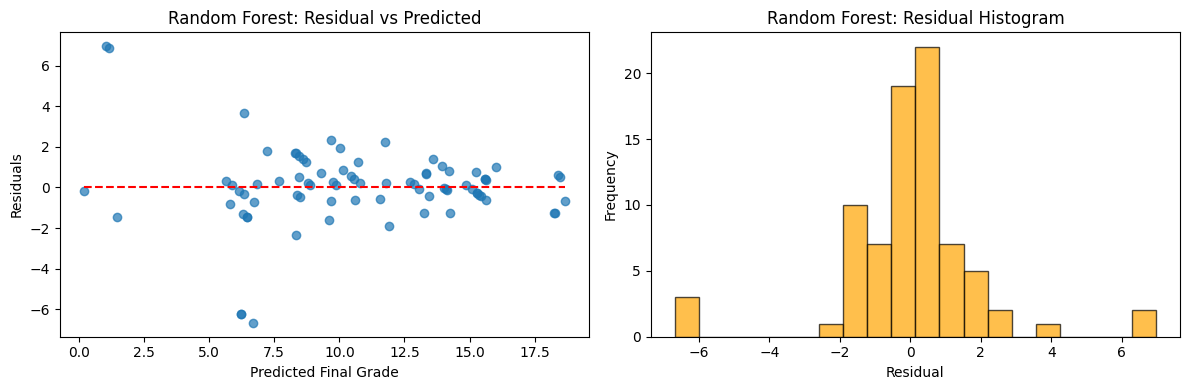

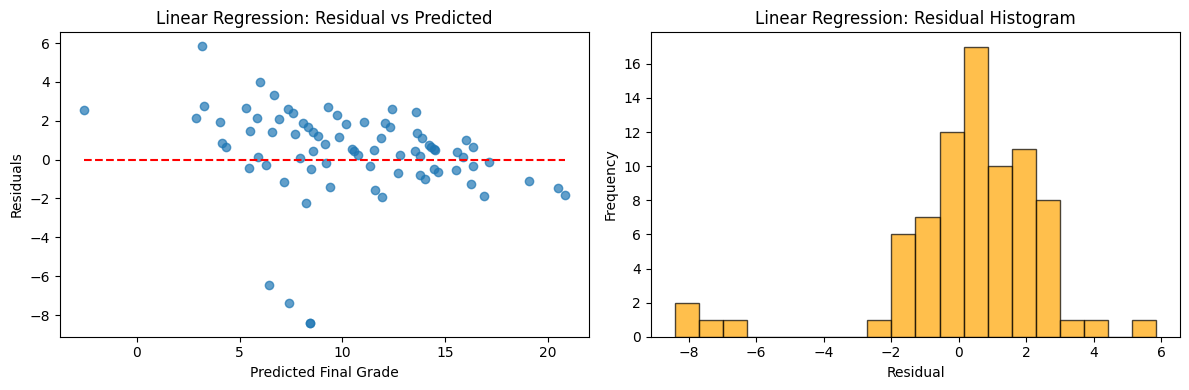

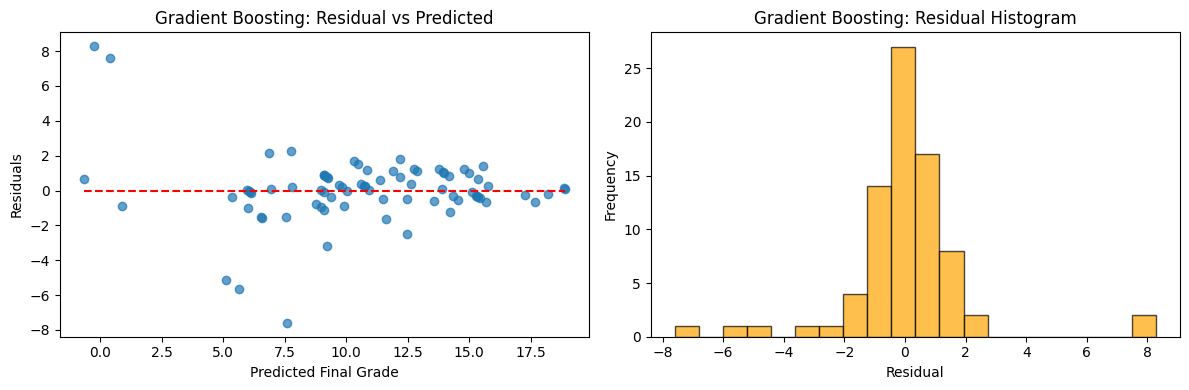

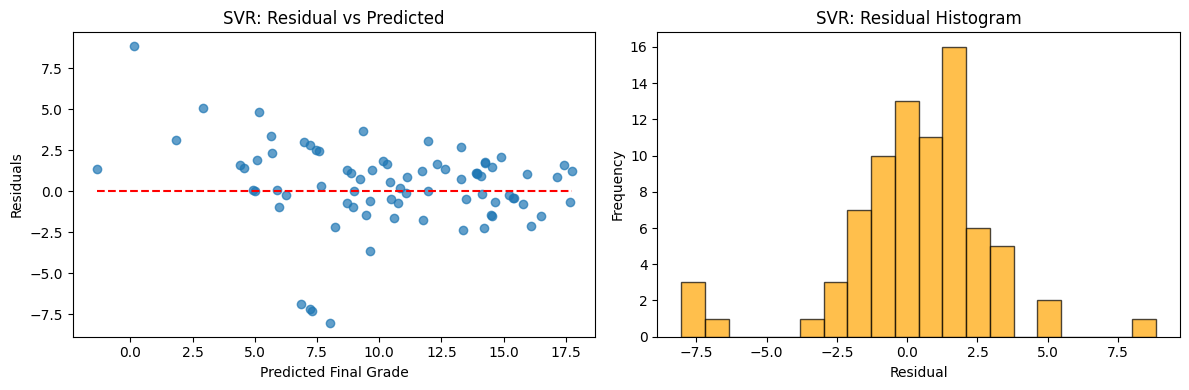

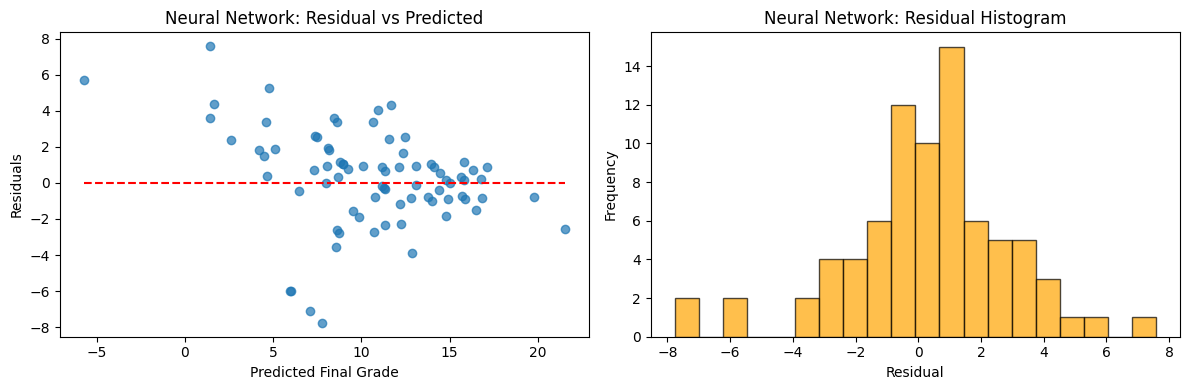

In [ ]:
# Residual vs Predicted + Density overlay
for name, model in models.items():
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    # Residual vs Predicted
    ax[0].scatter(y_pred, residuals, alpha=0.7)
    ax[0].hlines(y=0, xmin=min(y_pred), xmax=max(y_pred), colors='r', linestyles='dashed')
    ax[0].set_xlabel("Predicted Final Grade")
    ax[0].set_ylabel("Residuals")
    ax[0].set_title(f"{name}: Residual vs Predicted")

    # Histogram of Residuals
    ax[1].hist(residuals, bins=20, alpha=0.7, color='orange', edgecolor='black')
    ax[1].set_xlabel("Residual")
    ax[1].set_ylabel("Frequency")
    ax[1].set_title(f"{name}: Residual Histogram")

    plt.tight_layout()
    plt.show()
